# 2 — Main Network Criticality Analysis, Costa Rica (Single Point of Failure)

## Purpose
Quantify the criticality of every section of the Costa Rican main road network through asingle-point-of-failure (SPOF) percolation analysis. Each physical road is removed in turn(together with its reverse edge) and the population-weighted origin–destination travel timesare recomputed. The resulting disruption is expressed as vehicle / passenger / tonnage hoursand kilometres lost.

## Inputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/network/main_network_directed.gpkg`| Directed, AADT-attributed road network produced in 1b (EPSG:8908) |
| `input_files/CENTROS_POBLACION/centros_poblados_localidades.shp` | Locality points with INEC projected population (`INEC_PROY`, EPSG:8908)|

## Outputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/travel_disruptions/criticality_results.gpkg` | Per-edge SPOF criticality metrics |
| `figures/SPOF_results_2x2.png` | Average delay, VHL, average detour, VKL |
| `figures/SPOF_PHL_THL_PKL_TKL.png` | Passenger / tonnage hours and kilometres lost |
| `figures/SPOF_PHL_TKL_snapped_localities.png` | PHL and TKL map with snapped localities coloured by distance to the network |
| `figures/SPOF_by_road_type_boxplot.png` | Disruption by road class (box) |
| `figures/SPOF_by_road_type_violin.png` | Disruption by road class (violin) |
| `figures/SPOF_AADT_vs_criticality.png` | AADT vs criticality with regression |

## Key processing steps
1. **Load network** — read the directed GeoPackage and build a directed igraph graph on   `from_id` / `to_id`, carrying only routing attributes.
2. **Origin–destination nodes** — load locality points, snap each to the nearest network node,   aggregate `INEC_PROY` per node.
3. **Baseline matrices** — all-pairs shortest paths weighted by `fft`(road_length / speed) (hours) and `road_length` (km).
4. **Travel demand** — gravity model: demand ∝ Pop_o × Pop_d × exp(−decay × normalised distance).
5. **SPOF percolation** — remove each `physical_edge_id` group, recompute the OD time matrix,   summarise isolated / unaffected / delayed trips and demand-weighted disruption.
6. **Criticality metrics** — VHL / VKL from `total_aadt`, plus PHL / THL / PKL / TKL from the   seven Costa Rican traffic categories.
7. **Save & visualise**.## Assumptions recorded in this notebook- Everything stays in **EPSG:8908** (CR-SIRGAS / CRTM05, metres); Web Mercator is used only for basemaps.- A share of AADT is imputed in 1b — see the `aadt_imputed` flag.- The isolation penalty is **derived from the observed maximum baseline travel time**, not hard-coded.- Passenger and freight factors are defined once in `PASSENGER_FACTORS` / `FREIGHT_FACTORS`;  `pickup_trucks` is counted on both sides, and there is no articulated-vehicle class in the CR data.

## 1. Imports and configuration

In [1]:
# Standard library
import warnings
from pathlib import Path

# Third-party - data and scientific computing
import contextily as cx
import geopandas as gpd
import igraph as ig
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from tqdm import tqdm

# Shapely
import shapely
from shapely import STRtree

# Matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=RuntimeWarning)

In [2]:
# ---- Paths -------------------------------------------------------------
BASE_DIR = Path.cwd().parent          # notebook lives in /notebooks
data_path = BASE_DIR / "input_files"
figure_path = BASE_DIR / "figures"
intermediate_path = BASE_DIR / "intermediate_results"

network_gpkg = intermediate_path / "gpkg" / "network" / "main_network_directed.gpkg"
population_shp = data_path / "CENTROS_POBLACION" / "centros_poblados_localidades.shp"

criticality_results_path = (
    intermediate_path / "gpkg" / "travel_disruptions" / "criticality_results.gpkg"
)

figure_path.mkdir(parents=True, exist_ok=True)
criticality_results_path.parent.mkdir(parents=True, exist_ok=True)

# ---- Constants ---------------------------------------------------------
WORKING_EPSG = 8908          # CR-SIRGAS / CRTM05, metres
DIST_DECAY = 1.0             # gravity model decay
MAX_TRIPS = 25_000           # scaling of the busiest OD pair
ISOLATION_PENALTY_FACTOR = 2.0   # multiple of max baseline OD time (see section 6)
FAR_SNAP_WARN_M = 5_000      # localities snapping further than this are reported

# Routing attributes carried onto graph edges. Deliberately minimal: the
# percolation loop copies the graph once per iteration, so attaching geometry
# or the full attribute table would be very expensive.
GRAPH_EDGE_ATTRS = ["id", "physical_edge_id", "road_length", "fft"]

for p in (network_gpkg, population_shp):
    if not p.exists():
        raise FileNotFoundError(
            f"Missing input: {p}\n"
            "If this path lives on OneDrive, make sure the folder is downloaded locally "
            "('Always keep on this device') — cloud placeholders cannot be opened."
        )

print(f"Base directory : {BASE_DIR}")
print(f"Network        : {network_gpkg}")
print(f"Population     : {population_shp}")

Base directory : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR
Network        : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/gpkg/network/main_network_directed.gpkg
Population     : /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/input_files/CENTROS_POBLACION/centros_poblados_localidades.shp


## 2. Load and validate the directed network
The network comes from 1b and is already directed, AADT-attributed, speed-attributed andstrongly connected. This section re-validates that contract before anything depends on it.

In [3]:
edges = gpd.read_file(network_gpkg, layer="main_network_directed")

print(f"Directed edges : {len(edges):,}")
print(f"CRS            : {edges.crs}")
print(f"Geometry types : {sorted(edges.geom_type.unique())}")

# --- contract checks ----------------------------------------------------
required = [
    "from_id", "to_id", "id", "physical_edge_id", "direction_side",
    "road_length", "fft", "speed", "total_aadt", "CLASE",
    "motorcycles", "pickup_trucks", "passenger_cars", "buses",
    "light_trucks", "medium_trucks", "heavy_trucks",
]
missing = [c for c in required if c not in edges.columns]
assert not missing, f"Missing required columns: {missing}"

assert edges.crs is not None and edges.crs.to_epsg() == WORKING_EPSG, (
    f"Expected EPSG:{WORKING_EPSG}, found {edges.crs}"
)
assert edges.crs.axis_info[0].unit_name == "metre", "Working CRS must be metric"

for col in ["from_id", "to_id", "id", "physical_edge_id", "road_length", "fft"]:
    assert edges[col].notna().all(), f"{col} contains nulls"

assert (edges["road_length"] > 0).all(), "road_length must be strictly positive"
assert np.isfinite(edges["fft"]).all() and (edges["fft"] > 0).all(), "fft must be finite and positive"
assert edges["id"].is_unique, "edge id must be unique"

# CLASE carries nulls in the source; label them so groupby/plots keep them visible.
edges["CLASE"] = edges["CLASE"].fillna("Sin clasificar")

print("\nRoad classes:")
print(edges["CLASE"].value_counts().to_string())
print(f"\nTotal directed length : {edges['road_length'].sum():,.0f} km")
print(f"Unique physical roads : {edges['physical_edge_id'].nunique():,}")
print(f"AADT imputed edges    : {int(edges['aadt_imputed'].sum()):,} "
      f"({edges['aadt_imputed'].mean() * 100:.1f}%)")

Directed edges : 9,764
CRS            : EPSG:8908
Geometry types : ['LineString']

Road classes:
CLASE
Local             4223
Secundaria        2451
Terciaria         1451
Primaria          1393
Sin clasificar     246

Total directed length : 29,528 km
Unique physical roads : 5,012
AADT imputed edges    : 3,743 (38.3%)


In [4]:
# --- build the directed graph ------------------------------------------
# igraph's TupleList takes the FIRST TWO columns as the edge endpoints, so the
# column order here is load-bearing. Selecting explicitly (rather than relying
# on the incoming column order) is what keeps the graph meaningful.
graph_cols = ["from_id", "to_id"] + GRAPH_EDGE_ATTRS
assert graph_cols[0] == "from_id" and graph_cols[1] == "to_id"

graph_frame = edges[graph_cols]
graph = ig.Graph.TupleList(
    graph_frame.itertuples(index=False),
    edge_attrs=GRAPH_EDGE_ATTRS,
    directed=True,
)

print(f"Graph vertices : {graph.vcount():,}")
print(f"Graph edges    : {graph.ecount():,}")
assert graph.ecount() == len(edges), "Edge count mismatch — check column ordering"

# 1b guarantees a strongly connected giant component; a failure here means the
# network input is stale rather than that the analysis is wrong.
n_strong = len(graph.connected_components(mode="strong"))
print(f"Strong components : {n_strong}")
assert n_strong == 1, (
    f"Graph is not strongly connected ({n_strong} components) — "
    "re-run 1b to regenerate main_network_directed.gpkg"
)

Graph vertices : 3,909
Graph edges    : 9,764
Strong components : 1


In [5]:
# --- sister-edge pairing on physical_edge_id ---------------------------
# Pairing by reversed (source, target) mis-handles parallel edges. The 1b
# contract is exactly one directed edge per Unidireccional road and exactly
# two per Bidireccional road, so physical_edge_id is the reliable key.
edge_index_by_id = {eid: i for i, eid in enumerate(graph.es["id"])}
physical_groups = (
    pd.Series(graph.es["id"], name="id")
    .groupby(pd.Series(graph.es["physical_edge_id"], name="physical_edge_id"))
    .apply(list)
)

group_sizes = physical_groups.map(len).value_counts().sort_index()
print("Directed edges per physical road:")
print(group_sizes.to_string())
assert set(group_sizes.index) <= {1, 2}, "physical_edge_id groups must contain 1 or 2 edges"

print(f"\nPhysical roads to test : {len(physical_groups):,}")

Directed edges per physical road:
id
1     260
2    4752

Physical roads to test : 5,012


## 3. Load and audit the locality population layer
`INEC_PROY` is the INEC projected population per locality. The layer is already in EPSG:8908,so no reprojection is required — but the CRS is asserted rather than assumed, and `set_crs`is never used (it would silently relabel and displace the points).

In [6]:
localities = gpd.read_file(population_shp)

print(f"Localities     : {len(localities):,}")
print(f"CRS            : {localities.crs}")
print(f"Geometry types : {sorted(localities.geom_type.unique())}")
print(f"\nColumns: {list(localities.columns)}")
print("\nNull counts:")
print(localities.isna().sum().to_string())
print("\nSample:")
print(localities[["NOMBRE", "PROVINCIA", "CANTÓN", "TIPO", "INEC_PROY"]].head().to_string(index=False))

Localities     : 493
CRS            : EPSG:8908
Geometry types : ['Point']

Columns: ['gml_id', 'OBJECTID', 'CÓDIGO', 'TIPO', 'NOMBRE', 'NOMBRE_NO_', 'FUENTE', 'CÓDIGO_DTA', 'CÓDIGO_DE_', 'CÓDIGO_D_1', 'PROVINCIA', 'CANTÓN', 'DISTRITO', 'INEC_PROY', 'geometry']

Null counts:
gml_id        0
OBJECTID      0
CÓDIGO        0
TIPO          0
NOMBRE        0
NOMBRE_NO_    0
FUENTE        0
CÓDIGO_DTA    0
CÓDIGO_DE_    0
CÓDIGO_D_1    0
PROVINCIA     0
CANTÓN        0
DISTRITO      0
INEC_PROY     0
geometry      0

Sample:
        NOMBRE  PROVINCIA         CANTÓN                         TIPO  INEC_PROY
     La Cuesta Puntarenas     Corredores Poblado/Cabecera de Distrito       5531
        Laurel Puntarenas     Corredores Poblado/Cabecera de Distrito      12566
        Canoas Puntarenas     Corredores Poblado/Cabecera de Distrito      16230
Puerto Jiménez Puntarenas Puerto Jiménez    Ciudad/Cabecera de Cantón      13765
         Neily Puntarenas     Corredores    Ciudad/Cabecera de Cantón 

In [7]:
POP_COL = "INEC_PROY"
NAME_COL = "NOMBRE"

assert localities.crs is not None and localities.crs.to_epsg() == WORKING_EPSG, (
    f"Expected EPSG:{WORKING_EPSG}, found {localities.crs}"
)

# Reproject only if needed. Never set_crs — the layer is already projected.
if localities.crs.to_epsg() != edges.crs.to_epsg():
    localities = localities.to_crs(edges.crs)

# Points already; take centroids only if the layer is polygonal.
if localities.geom_type.isin(["Polygon", "MultiPolygon"]).any():
    print("Polygonal geometry detected — using centroids")
    localities = localities.copy()
    localities["geometry"] = localities.geometry.centroid

n_before = len(localities)
localities[POP_COL] = pd.to_numeric(localities[POP_COL], errors="coerce")
OD_nodes = localities.loc[
    localities[POP_COL].notna() & (localities[POP_COL] > 0) & localities.geometry.notna()
].copy()
dropped = n_before - len(OD_nodes)

OD_nodes = OD_nodes.rename(columns={POP_COL: "population"}).reset_index(drop=True)

# A readable label. NOMBRE repeats across cantons, so qualify it.
OD_nodes["label"] = OD_nodes[NAME_COL].astype(str) + " (" + OD_nodes["CANTÓN"].astype(str) + ")"

print(f"Localities retained : {len(OD_nodes):,} (dropped {dropped} null/non-positive)")
print(f"Total population    : {OD_nodes['population'].sum():,.0f}")
print(f"Population range    : {OD_nodes['population'].min():,.0f} – {OD_nodes['population'].max():,.0f}")
print("\nLargest localities:")
print(OD_nodes.nlargest(8, "population")[["label", "PROVINCIA", "population"]].to_string(index=False))

Localities retained : 493 (dropped 0 null/non-positive)
Total population    : 5,167,278
Population range    : 414 – 90,730

Largest localities:
                                   label  PROVINCIA  population
                        Pavas (San José)   San José       90730
                       Liberia (Liberia) Guanacaste       68040
               Hatillo Centro (San José)   San José       60681
                 San Francisco (Heredia)    Heredia       60480
                     San José (Alajuela)   Alajuela       54105
                           Limón (Limón)      Limón       53629
San Isidro de El General (Pérez Zeledón)   San José       46556
                     Alajuela (Alajuela)   Alajuela       46314


## 4. Snap localities to network nodes
Both layers are metric and in the same CRS, so snap distances below are directly interpretablein metres.

In [8]:
# Network node geometry, keyed by the node ids used in the graph.
vertex_lookup = {name: idx for idx, name in enumerate(graph.vs["name"])}

start_points = shapely.get_point(edges.geometry.values, 0)
end_points = shapely.get_point(edges.geometry.values, -1)

node_geom = {}
node_geom.update(dict(zip(edges["from_id"].to_numpy(), start_points)))
node_geom.update(dict(zip(edges["to_id"].to_numpy(), end_points)))

nodes = gpd.GeoDataFrame(
    {"node_id": list(node_geom.keys())},
    geometry=list(node_geom.values()),
    crs=edges.crs,
)
missing_nodes = [n for n in nodes["node_id"] if n not in vertex_lookup]
assert not missing_nodes, f"{len(missing_nodes)} node ids absent from the graph"
nodes["vertex_id"] = nodes["node_id"].map(vertex_lookup)

print(f"Network nodes : {len(nodes):,}")

# Nearest network node per locality.
nodes_sindex = STRtree(nodes.geometry.values)
nearest_idx = nodes_sindex.nearest(OD_nodes.geometry.values)
OD_nodes["vertex_id"] = nodes["vertex_id"].to_numpy()[nearest_idx]
OD_nodes["snap_distance_m"] = shapely.distance(
    OD_nodes.geometry.values, nodes.geometry.to_numpy()[nearest_idx]
)

Network nodes : 3,909


Snap distance (metres):
  min / median / mean / max : 8 / 247 / 618 / 16,873
  p75 : 687
  p90 : 1,425
  p95 : 2,144
  p99 : 5,380

Localities snapping further than 5,000 m : 6 (1.2%)
                          label  PROVINCIA  population  snap_distance_m
Puerto Jiménez (Puerto Jiménez) Puntarenas       13765     16872.644962
    Barra del Colorado (Pococí)      Limón        5025     12342.366247
           Nancite (Puntarenas) Puntarenas        1675      8158.460803
              Cabanga (Guatuso)   Alajuela        1109      7304.365178
             Amubri (Talamanca)      Limón        8853      5845.082926
               Delicias (Upala)   Alajuela        5413      5340.043189


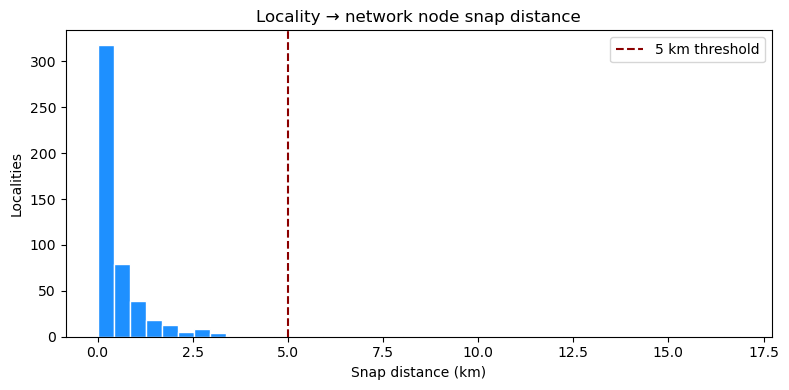

In [9]:
snap = OD_nodes["snap_distance_m"]
print("Snap distance (metres):")
print(f"  min / median / mean / max : {snap.min():,.0f} / {snap.median():,.0f} / "
      f"{snap.mean():,.0f} / {snap.max():,.0f}")
for q in (0.75, 0.90, 0.95, 0.99):
    print(f"  p{int(q * 100)} : {snap.quantile(q):,.0f}")

far = OD_nodes.loc[snap > FAR_SNAP_WARN_M]
print(f"\nLocalities snapping further than {FAR_SNAP_WARN_M:,} m : {len(far)} "
      f"({len(far) / len(OD_nodes) * 100:.1f}%)")
if len(far):
    print(far.nlargest(10, "snap_distance_m")[
        ["label", "PROVINCIA", "population", "snap_distance_m"]
    ].to_string(index=False))

# Policy: far-snapping localities are RETAINED and flagged, not dropped. They are
# real population that depends on the network; dropping them would understate
# disruption in exactly the remote areas where isolation matters most. The flag is
# kept so the assumption stays visible downstream.
OD_nodes["snap_far"] = snap > FAR_SNAP_WARN_M

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(snap / 1000, bins=40, color="#1E90FF", edgecolor="white")
ax.axvline(FAR_SNAP_WARN_M / 1000, color="#8B0000", linestyle="--",
           label=f"{FAR_SNAP_WARN_M / 1000:.0f} km threshold")
ax.set_xlabel("Snap distance (km)")
ax.set_ylabel("Localities")
ax.set_title("Locality → network node snap distance")
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# Aggregate population onto shared network nodes.
grouped_OD = (
    OD_nodes.groupby("vertex_id")
    .agg(
        geometry=("geometry", "first"),
        population=("population", "sum"),
        label=("label", "first"),
        n_localities=("label", "size"),
    )
    .reset_index()
)
grouped_OD = gpd.GeoDataFrame(grouped_OD, geometry="geometry", crs=edges.crs)

collapsed = len(OD_nodes) - len(grouped_OD)
print(f"OD nodes after aggregation : {len(grouped_OD):,} "
      f"({collapsed} localities collapsed onto shared nodes)")
assert grouped_OD["population"].sum() == OD_nodes["population"].sum(), "population lost in aggregation"
print(f"Population preserved       : {grouped_OD['population'].sum():,.0f}")
print(f"OD matrix size             : {len(grouped_OD)} x {len(grouped_OD)}")

OD nodes after aggregation : 485 (8 localities collapsed onto shared nodes)
Population preserved       : 5,167,278
OD matrix size             : 485 x 485


## 5. Baseline travel matrices and gravity demand

In [11]:
def run_shortest_paths(graph, OD_nodes, weighting="fft"):
    """All-pairs shortest path matrix between OD vertices under the given edge weight."""
    vertex_ids = OD_nodes.vertex_id.values
    return np.matrix(graph.distances(source=vertex_ids, target=vertex_ids, weights=weighting))


def create_demand(node_pop, OD_orig, dist_decay=DIST_DECAY, maxtrips=MAX_TRIPS):
    """Gravity model: Demand_a,b = Pop_a * Pop_b * exp(-decay * normalised distance).

    Vectorised equivalent of the original double loop. Note that demand enters the
    analysis only as weights in a weighted average, so its absolute scale cancels out
    of the reported disruption; `maxtrips` matters only through the np.ceil rounding
    below, which would flatten the weights if it were set very low.
    """
    normalized_dist = np.asarray(OD_orig / OD_orig.max())
    pop = np.asarray(node_pop, dtype=float)
    demand = np.outer(pop, pop) * np.exp(-dist_decay * normalized_dist)
    np.fill_diagonal(demand, 0)
    demand = (demand / demand.max()) * maxtrips
    return np.ceil(demand).astype(int)

In [12]:
# Baseline matrices. OD_base_time keeps a zero diagonal and drives the demand model;
# the NaN-diagonal copies are used for the disruption comparison.
OD_base_time = run_shortest_paths(graph, grouped_OD, weighting="fft")
assert np.isfinite(OD_base_time).all(), "Non-finite baseline travel time — graph not strongly connected?"

demand = create_demand(grouped_OD.population.values, OD_base_time)

OD_orig_time = OD_base_time.copy()
OD_orig_dist = run_shortest_paths(graph, grouped_OD, weighting="road_length")
assert np.isfinite(OD_orig_dist).all(), "Non-finite baseline distance"

np.fill_diagonal(OD_orig_time, np.nan)
np.fill_diagonal(OD_orig_dist, np.nan)

# Implied speed per OD pair (km/h), used to convert delay into detour distance.
speed_ratio = np.array(OD_orig_dist) / np.array(OD_orig_time)

max_baseline_hours = float(np.nanmax(OD_orig_time))
ISOLATION_PENALTY_HOURS = float(np.ceil(max_baseline_hours * ISOLATION_PENALTY_FACTOR))

print(f"Baseline travel time  : max {max_baseline_hours:.2f} h, "
      f"mean {np.nanmean(OD_orig_time):.2f} h")
print(f"Baseline distance     : max {np.nanmax(OD_orig_dist):,.0f} km, "
      f"mean {np.nanmean(OD_orig_dist):,.0f} km")
print(f"Implied speed         : mean {np.nanmean(speed_ratio):.1f} km/h")
print(f"\nIsolation penalty     : {ISOLATION_PENALTY_HOURS:.0f} h "
      f"({ISOLATION_PENALTY_FACTOR:g} x the {max_baseline_hours:.2f} h maximum baseline trip)")
print("  Derived from the data so that being cut off is always costlier than the "
      "longest legitimate journey.")
print(f"\nDemand: max {demand.max():,} trips/day on the busiest pair, "
      f"{demand.sum():,} total")

Baseline travel time  : max 10.38 h, mean 2.82 h
Baseline distance     : max 552 km, mean 142 km
Implied speed         : mean 49.8 km/h

Isolation penalty     : 21 h (2 x the 10.38 h maximum baseline trip)
  Derived from the data so that being cut off is always costlier than the longest legitimate journey.

Demand: max 25,000 trips/day on the busiest pair, 99,439,323 total


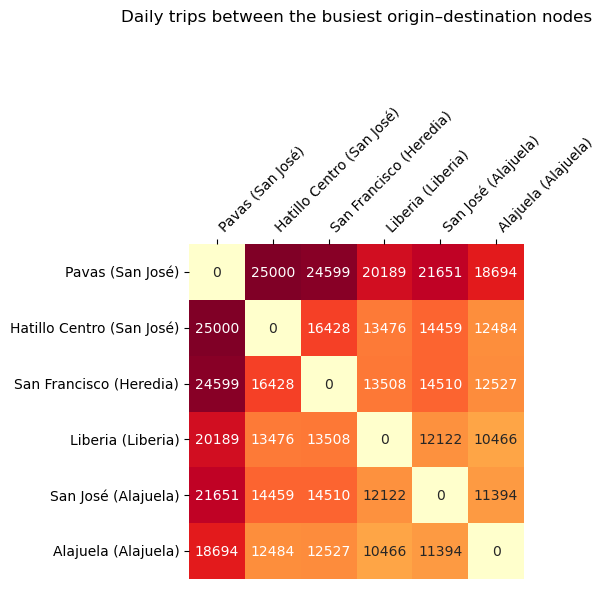

In [13]:
# Demand heatmap for the busiest OD nodes.
row_sums = np.asarray(demand).sum(axis=1)
top_idx = np.argsort(row_sums)[::-1][:6]
sub = np.asarray(demand)[np.ix_(top_idx, top_idx)]
labels = grouped_OD.loc[top_idx, "label"].tolist()

plt.figure(figsize=(8, 6))
sns.heatmap(sub, annot=True, fmt=".0f", cmap="YlOrRd",
            xticklabels=labels, yticklabels=labels, square=True, cbar=False)
plt.xlabel("")
plt.ylabel("")
plt.gca().xaxis.tick_top()
plt.xticks(rotation=45, ha="left")
plt.yticks(rotation=0)
plt.title("Daily trips between the busiest origin–destination nodes", pad=60)
plt.tight_layout()
plt.show()

## 6. Single-point-of-failure percolation
Each physical road is removed together with its reverse edge, and the OD travel-time matrix isrecomputed. Trips left without any route receive `ISOLATION_PENALTY_HOURS`, derived above.
Note on `SummariseOD`: for isolated OD pairs the distance disruption is set to the removedroad's own length. That is a placeholder, not a measured detour — no route exists, so nodetour distance can be computed.

In [14]:
def SummariseOD(OD_time, fail_value, demand, baseline_time, speed_ratio, edge_length,
                frac_counter, distance_disruption, time_disruption):
    """Disruption metrics including demand-weighted average time and distance disruption."""
    adj_time = OD_time - baseline_time

    total_trips = (baseline_time.shape[0] * baseline_time.shape[1]) - baseline_time.shape[0]

    isolated_trips_sum = OD_time[OD_time == fail_value].shape[1]
    pct_isolated = (isolated_trips_sum / total_trips) * 100

    time_unaffected_trips = OD_time[OD_time == baseline_time]
    unaffected_trips = np.array(time_unaffected_trips).shape[1]
    pct_unaffected = (unaffected_trips / total_trips) * 100

    delayed_mask = (np.array(OD_time) != np.array(baseline_time)) & (~np.isnan(np.array(OD_time)))

    delayed_times = np.array(adj_time)[delayed_mask]
    delayed_speeds = np.array(speed_ratio)[delayed_mask]
    delayed_demands = np.array(demand)[delayed_mask]

    isolated_within_delayed = np.array(OD_time)[delayed_mask] == fail_value

    # Rerouted trips: delay x implied speed. Isolated trips: placeholder (see markdown).
    delayed_dists = delayed_times * delayed_speeds
    delayed_dists[isolated_within_delayed] = edge_length

    delayed_trips = delayed_times.shape[0]
    pct_delayed = (delayed_trips / total_trips) * 100

    if len(delayed_times) > 0 and delayed_demands.sum() > 0:
        average_time_disruption = np.average(delayed_times, weights=delayed_demands)
        average_dist_disruption = np.average(delayed_dists, weights=delayed_demands)
    else:
        # No OD pair was delayed at all: the road carries no shortest path between
        # any pair of population centres, so its failure costs zero measured time
        # and distance. This is a real result (a fully redundant road), not missing
        # data, so it is recorded as 0 rather than NaN — NaN would silently drop
        # these roads out of the maps, class breaks and summary statistics.
        average_time_disruption = 0.0
        average_dist_disruption = 0.0

    return (frac_counter, pct_isolated, pct_unaffected, pct_delayed,
            average_time_disruption, average_dist_disruption,
            distance_disruption, time_disruption)

In [15]:
tot_edge_length = float(np.sum(graph.es["road_length"]))
tot_edge_time = float(np.sum(graph.es["fft"]))

# One timed iteration first, so the full run has a realistic ETA.
import time

_probe_ids = physical_groups.iloc[0]
_probe_idx = [edge_index_by_id[i] for i in _probe_ids]
_t0 = time.perf_counter()
_g = graph.copy()
_g.delete_edges(_probe_idx)
_ = run_shortest_paths(_g, grouped_OD, weighting="fft")
_per_iter = time.perf_counter() - _t0

print(f"Single iteration : {_per_iter:.3f} s")
print(f"Physical roads   : {len(physical_groups):,}")
print(f"Estimated total  : {_per_iter * len(physical_groups) / 60:.1f} min")

Single iteration : 1.158 s
Physical roads   : 5,012
Estimated total  : 96.7 min


In [16]:
result_df = []

for physical_id, edge_ids in tqdm(physical_groups.items(), total=len(physical_groups),
                                  desc="percolation"):
    edge_idx = [edge_index_by_id[i] for i in edge_ids]

    # Combined length of the physical road (both directions when bidirectional).
    edge_length = float(sum(graph.es[i]["road_length"] for i in edge_idx))

    exp_g = graph.copy()
    exp_g.delete_edges(edge_idx)

    cur_dis_length = 1 - (np.sum(exp_g.es["road_length"]) / tot_edge_length)
    cur_dis_time = 1 - (np.sum(exp_g.es["fft"]) / tot_edge_time)

    perc_matrix_time = run_shortest_paths(exp_g, grouped_OD, weighting="fft")
    np.fill_diagonal(perc_matrix_time, np.nan)
    perc_matrix_time[np.isinf(perc_matrix_time)] = ISOLATION_PENALTY_HOURS

    results = SummariseOD(
        perc_matrix_time, ISOLATION_PENALTY_HOURS, demand,
        OD_orig_time, speed_ratio, edge_length,
        physical_id, cur_dis_length, cur_dis_time,
    )
    result_df.append(results)

result_df = pd.DataFrame(result_df, columns=[
    "physical_edge_id", "pct_isolated", "pct_unaffected", "pct_delayed",
    "average_time_disruption", "average_dist_disruption",
    "distance_disruption", "time_disruption",
])

n_redundant = (result_df["pct_delayed"] == 0).sum()
print(f"\nPhysical roads tested   : {len(result_df):,}")
print(f"Roads causing isolation : {(result_df['pct_isolated'] > 0).sum():,}")
print(f"Fully redundant roads   : {n_redundant:,} "
      f"({n_redundant / len(result_df) * 100:.1f}%) — removal delays no OD pair, "
      "recorded as zero disruption")
print(result_df[["pct_isolated", "pct_unaffected", "pct_delayed",
                 "average_time_disruption", "average_dist_disruption"]].describe().to_string())

percolation:  50%|████▉     | 2487/5012 [13:34<13:46,  3.05it/s] 


KeyboardInterrupt: 

## 7. Criticality metrics
Disruption is measured per **physical road**, then joined back onto the directed edges on`physical_edge_id`, so both directions of a bidirectional road carry the same disruption.### Passenger and freight factorsThe Serbian formulation used an `articulated_vehicles` class that does not exist in the CostaRican data. The factors below are stated as explicit assumptions:- `pickup_trucks` is the second-largest CR category and serves both personal and goods  transport, so it is counted on **both** sides at reduced weight. Assigning it wholly to  passengers is the defensible alternative.- There is no articulated class, so the heaviest freight factor is 8.0 t. Costa Rican tonnage  results are therefore **not** comparable with the Serbian ones.

In [ ]:
# Passengers per vehicle, by category.
PASSENGER_FACTORS = {
    "motorcycles": 1.2,
    "passenger_cars": 2.0,
    "pickup_trucks": 2.0,
    "buses": 30.0,
}

# Tonnes of freight per vehicle, by category. No articulated class exists in the CR data.
FREIGHT_FACTORS = {
    "pickup_trucks": 0.3,
    "light_trucks": 1.2,
    "medium_trucks": 3.8,
    "heavy_trucks": 8.0,
}

print("Passenger factors (persons/vehicle):")
for k, v in PASSENGER_FACTORS.items():
    print(f"  {k:16} x {v}")
print("Freight factors (tonnes/vehicle):")
for k, v in FREIGHT_FACTORS.items():
    print(f"  {k:16} x {v}")

In [ ]:
gdf_results = edges.merge(result_df, on="physical_edge_id", how="left", validate="many_to_one")

assert len(gdf_results) == len(edges), "merge changed the row count"
assert gdf_results["average_time_disruption"].notna().all(), "unmatched edges after merge"

# Vehicle hours / kilometres lost.
gdf_results["vhl"] = gdf_results["average_time_disruption"] * gdf_results["total_aadt"]
gdf_results["vkl"] = gdf_results["average_dist_disruption"] * gdf_results["total_aadt"]

passengers = sum(gdf_results[col] * f for col, f in PASSENGER_FACTORS.items())
tonnes = sum(gdf_results[col] * f for col, f in FREIGHT_FACTORS.items())

gdf_results["phl"] = gdf_results["average_time_disruption"] * passengers
gdf_results["pkl"] = gdf_results["average_dist_disruption"] * passengers
gdf_results["thl"] = gdf_results["average_time_disruption"] * tonnes
gdf_results["tkl"] = gdf_results["average_dist_disruption"] * tonnes

for col in ["vhl", "vkl", "phl", "pkl", "thl", "tkl"]:
    assert np.isfinite(gdf_results[col]).all(), f"{col} contains non-finite values"
    assert (gdf_results[col] >= 0).all(), f"{col} contains negative values"

print(gdf_results[["average_time_disruption", "average_dist_disruption",
                   "vhl", "vkl", "phl", "thl", "pkl", "tkl"]].describe().to_string())

In [ ]:
ZERO_LABEL = "No disruption"


def data_driven_breaks(series, n_positive_classes=4):
    """Quantile class breaks computed over the strictly positive values only.

    Two reasons this is not a plain quantile cut over the whole distribution:

    1. The inherited Serbian bins were calibrated on a larger, higher-volume network
       and collapse almost every Costa Rican road into the lowest class.
    2. Around 40% of Costa Rican roads have *exactly* zero disruption (they carry no
       shortest path between population centres). A plain quantile cut puts several
       break points on top of each other at zero and produces a meaningless "0–0"
       class, which hides how large that group is. Zero therefore gets its own
       explicit class and the quantiles describe the roads that actually matter.
    """
    s = series.astype(float)
    pos = s[s > 0]
    if len(pos) == 0:
        return np.array([0.0, np.inf])
    qs = np.linspace(0, 1, n_positive_classes + 1)
    edges_ = np.unique(np.nanquantile(pos, qs))
    if len(edges_) < 2:
        edges_ = np.array([float(pos.min()), float(pos.max())])
    edges_[0] = 0.0        # positive classes open just above zero
    edges_[-1] = np.inf
    return edges_


def fmt_break(v):
    if not np.isfinite(v):
        return "+"
    a = abs(v)
    if a >= 1000:
        return f"{v / 1000:,.0f}K"
    if a >= 10:
        return f"{v:.0f}"
    if a >= 1:
        return f"{v:.1f}"
    if a == 0:
        return "0"
    return f"{v:.3g}"


def break_labels(breaks):
    return [f"{fmt_break(breaks[i])}–{fmt_break(breaks[i + 1])}"
            for i in range(len(breaks) - 1)]


def classify_metric(values, breaks):
    """Split into an explicit zero class plus the positive quantile classes."""
    labels = break_labels(breaks)
    out = pd.Series(ZERO_LABEL, index=values.index, dtype=object)
    positive = values > 0
    if positive.any():
        out.loc[positive] = pd.cut(
            values[positive], bins=breaks, labels=labels, include_lowest=False
        ).astype(object)
    return out, [ZERO_LABEL] + labels


MAP_METRICS = ["average_time_disruption", "vhl", "average_dist_disruption", "vkl",
               "phl", "thl", "pkl", "tkl"]

## 8. Figures

In [ ]:
# Index 0 is the explicit "No disruption" class; the rest run low → high.
# Remote basemap tiles can make notebook cells appear to hang with no output.
# Set USE_BASEMAP = True only when you are online and want the CartoDB background.
USE_BASEMAP = False

CLASS_WIDTHS = [0.4, 1.2, 1.8, 2.4, 3.0]
CLASS_COLORS = ["#cccccc", "#2b83ba", "#abdda4", "#fdae61", "#d7191c"]


def plot_metric_panel(ax, gdf_web, metric, title, legend_title):
    """Draw one criticality map panel, thickest/reddest = most disrupted."""
    breaks = METRIC_BREAKS[metric]
    classes, labels = classify_metric(gdf_web[metric], breaks)

    for i, label in enumerate(labels):
        subset = gdf_web[classes == label]
        if len(subset) == 0:
            continue
        subset.plot(ax=ax, color=CLASS_COLORS[i], linewidth=CLASS_WIDTHS[i],
                    alpha=0.85, zorder=2 + i)

    if USE_BASEMAP:
        print(f"Adding basemap tiles for {title}...", flush=True)
        cx.add_basemap(ax=ax, source=cx.providers.CartoDB.Positron, alpha=0.4, attribution=False)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=13, fontweight="bold")

    handles = [Line2D([0], [0], color=CLASS_COLORS[i], lw=max(CLASS_WIDTHS[i], 1.5),
                      label=labels[i]) for i in range(len(labels))]
    ax.legend(handles=handles, title=legend_title, loc="upper right", fontsize=8,
              title_fontsize=9, frameon=True, framealpha=0.9, facecolor="white",
              edgecolor="#cccccc")


# Collapse the directed network to one row per physical road.
#
# This is NOT a drop_duplicates: 1b splits a bidirectional road's traffic evenly
# across its two directed edges (aadt_direction_factor = 0.5), while a
# unidirectional road keeps all of it on a single edge (factor = 1.0). Keeping
# only one edge per road would therefore report half the traffic for
# bidirectional roads and all of it for unidirectional ones — two different
# scales in the same table. Traffic-derived quantities are summed over the
# road's directed edges to recover the full two-way daily figure; per-road
# quantities (disruption, length, attributes) are identical on both edges and
# are taken once.
SUM_COLS = ["total_aadt", "motorcycles", "pickup_trucks", "passenger_cars", "buses",
            "light_trucks", "medium_trucks", "heavy_trucks",
            "vhl", "vkl", "phl", "thl", "pkl", "tkl"]
FIRST_COLS = ["geometry", "CLASE", "NOMBRE", "ID_TRAMO", "ID_RUTA", "ADMIN",
              "NODO_INI", "NODO_FIN", "DIRECCION", "road_length", "speed",
              "aadt_imputed", "pct_isolated", "pct_unaffected", "pct_delayed",
              "average_time_disruption", "average_dist_disruption",
              "distance_disruption", "time_disruption"]

agg = {c: (c, "sum") for c in SUM_COLS}
agg.update({c: (c, "first") for c in FIRST_COLS})
physical_results = gdf_results.groupby("physical_edge_id", as_index=False).agg(**agg)
physical_results = gpd.GeoDataFrame(physical_results, geometry="geometry", crs=edges.crs)

n_bi = (gdf_results.groupby("physical_edge_id").size() == 2).sum()
print(f"Physical roads : {len(physical_results):,} ({n_bi:,} bidirectional, "
      f"{len(physical_results) - n_bi:,} unidirectional)")
print(f"Two-way AADT   : mean {physical_results['total_aadt'].mean():,.0f}, "
      f"max {physical_results['total_aadt'].max():,.0f}")

gdf_web = physical_results.to_crs(3857)

# Class breaks are derived from the per-road (two-way) values that are actually
# plotted, not from the per-direction values on gdf_results.
METRIC_BREAKS = {}
print("\nClass breaks (per physical road, two-way):")
for metric in MAP_METRICS:
    b = data_driven_breaks(physical_results[metric])
    METRIC_BREAKS[metric] = b
    n_zero = int((physical_results[metric] <= 0).sum())
    print(f"  {metric:26} zero: {n_zero / len(physical_results) * 100:4.1f}%  "
          f"positive breaks: {[fmt_break(x) for x in b]}")

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 16), facecolor="white")

panels = [
    ("average_time_disruption", "A. Average time delay", "Hours"),
    ("vhl", "B. Vehicle hours lost", "Vehicle-hours"),
    ("average_dist_disruption", "C. Average detour distance", "Kilometres"),
    ("vkl", "D. Vehicle kilometres lost", "Vehicle-km"),
]
for ax, (metric, title, legend_title) in zip(axes.ravel(), panels):
    plot_metric_panel(ax, gdf_web, metric, title, legend_title)

plt.tight_layout()
plt.savefig(figure_path / "SPOF_results_2x2.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 16), facecolor="white")

panels = [
    ("phl", "A. Passenger hours lost", "Passenger-hours"),
    ("thl", "B. Tonnage hours lost", "Tonne-hours"),
    ("pkl", "C. Passenger kilometres lost", "Passenger-km"),
    ("tkl", "D. Tonnage kilometres lost", "Tonne-km"),
]
for ax, (metric, title, legend_title) in zip(axes.ravel(), panels):
    plot_metric_panel(ax, gdf_web, metric, title, legend_title)

plt.tight_layout()
plt.savefig(figure_path / "SPOF_PHL_THL_PKL_TKL.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
## Plot map PHL and TKL with the localities that are snapped
# 1. Red - Far away from the network.
# 2. Blue - Within the network.

localities_web = OD_nodes.to_crs(3857)
within_localities = localities_web[~localities_web["snap_far"]]
far_localities = localities_web[localities_web["snap_far"]]
threshold_km = FAR_SNAP_WARN_M / 1000

print("Preparing PHL/TKL snapped-localities map...", flush=True)

combined_bounds = np.vstack([gdf_web.total_bounds, localities_web.total_bounds])
minx, miny = combined_bounds[:, :2].min(axis=0)
maxx, maxy = combined_bounds[:, 2:].max(axis=0)
pad_x = (maxx - minx) * 0.03
pad_y = (maxy - miny) * 0.03


def plot_metric_panel_without_basemap(ax, gdf_web, metric, title, legend_title):
    """Draw one criticality map panel without fetching remote basemap tiles."""
    breaks = METRIC_BREAKS[metric]
    classes, labels = classify_metric(gdf_web[metric], breaks)

    for i, label in enumerate(labels):
        subset = gdf_web[classes == label]
        if len(subset) == 0:
            continue
        subset.plot(ax=ax, color=CLASS_COLORS[i], linewidth=CLASS_WIDTHS[i],
                    alpha=0.85, zorder=2 + i)

    ax.set_xlim(minx - pad_x, maxx + pad_x)
    ax.set_ylim(miny - pad_y, maxy + pad_y)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_facecolor("#f7f7f7")

    handles = [Line2D([0], [0], color=CLASS_COLORS[i], lw=max(CLASS_WIDTHS[i], 1.5),
                      label=labels[i]) for i in range(len(labels))]
    criticality_legend = ax.legend(handles=handles, title=legend_title, loc="upper right",
                                   fontsize=8, title_fontsize=9, frameon=True,
                                   framealpha=0.9, facecolor="white", edgecolor="#cccccc")
    ax.add_artist(criticality_legend)


fig, axes = plt.subplots(1, 2, figsize=(16, 9), facecolor="white")
panels = [
    ("phl", "Passenger hours lost (PHL)", "Passenger-hours"),
    ("tkl", "Tonnage kilometres lost (TKL)", "Tonne-km"),
]

for ax, (metric, title, legend_title) in zip(axes, panels):
    print(f"Drawing {metric.upper()} panel...", flush=True)
    if not within_localities.empty:
        within_localities.plot(
            ax=ax,
            color="#707070CD",
            markersize=16,
            alpha=0.55,
            edgecolor="black",
            linewidth=0.2,
            zorder=8,
        )
    if not far_localities.empty:
        far_localities.plot(
            ax=ax,
            color="#060606",
            markersize=16,
            alpha=0.95,
            edgecolor="black",
            linewidth=0.4,
            zorder=9,
        )
    plot_metric_panel_without_basemap(ax, gdf_web, metric, title, legend_title)

    locality_legend = [
        Line2D([0], [0], marker="o", color="white", markerfacecolor="#0a0a0a",
               markeredgecolor="black", markersize=8, linestyle="None",
               label=f"Far away > {threshold_km:g} km"),
        Line2D([0], [0], marker="o", color="white", markerfacecolor="#707070CD",
               markeredgecolor="black", markersize=8, linestyle="None",
               label=f"Within <= {threshold_km:g} km"),
    ]
    ax.legend(handles=locality_legend, title="Snapped localities", loc="lower left",
              fontsize=8, title_fontsize=9, frameon=True, framealpha=0.9,
              facecolor="white", edgecolor="#cccccc")

plt.tight_layout()
print("Saving figure...", flush=True)
plt.savefig(figure_path / "SPOF_PHL_TKL_snapped_localities.png", dpi=300, bbox_inches="tight")
plt.show()

OD_nodes["snap_far"].value_counts().rename(index={False: "Within network", True: "Far away from network"})

In [ ]:
CLASS_ORDER = [c for c in ["Primaria", "Secundaria", "Terciaria", "Local", "Sin clasificar"]
               if c in physical_results["CLASE"].unique()]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor="white")
panels = [
    ("average_time_disruption", "Average time delay (hours)"),
    ("phl", "Passenger hours lost"),
    ("average_dist_disruption", "Average detour (km)"),
    ("pkl", "Passenger kilometres lost"),
]
for ax, (metric, title) in zip(axes.ravel(), panels):
    physical_results.boxplot(column=metric, by="CLASE", ax=ax, grid=False)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Criticality by road class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(figure_path / "SPOF_by_road_type_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), facecolor="white")
for ax, (metric, title) in zip(axes.ravel(), panels):
    sns.violinplot(data=physical_results, x="CLASE", y=metric, order=CLASS_ORDER,
                   ax=ax, cut=0, hue="CLASE", legend=False, palette="Set2")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Criticality distribution by road class", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(figure_path / "SPOF_by_road_type_violin.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor="white")

for ax, metric, label in [(ax1, "phl", "Passenger hours lost"),
                          (ax2, "pkl", "Passenger kilometres lost")]:
    observed = physical_results[~physical_results["aadt_imputed"]]
    imputed = physical_results[physical_results["aadt_imputed"]]

    ax.scatter(observed["total_aadt"], observed[metric], s=10, alpha=0.5,
               color="#1E90FF", label="AADT observed")
    ax.scatter(imputed["total_aadt"], imputed[metric], s=10, alpha=0.5,
               color="#d7191c", label="AADT imputed")

    valid = physical_results[["total_aadt", metric]].dropna()
    slope, intercept, r, p, se = stats.linregress(valid["total_aadt"], valid[metric])
    xs = np.linspace(valid["total_aadt"].min(), valid["total_aadt"].max(), 100)
    ax.plot(xs, intercept + slope * xs, color="black", lw=1.5,
            label=f"fit: r²={r ** 2:.3f}")

    ax.set_xlabel("Total AADT (vehicles/day)")
    ax.set_ylabel(label)
    ax.set_title(f"AADT vs {label.lower()}", fontsize=12, fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(figure_path / "SPOF_AADT_vs_criticality.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Save criticality results

In [ ]:
preferred_columns = [
    # identity / topology
    "id", "physical_edge_id", "source_part_id", "from_id", "to_id", "direction_side",
    # source attributes
    "ID_TRAMO", "TRAMO_UID", "ID_RUTA", "NOMBRE", "CLASE", "ADMIN",
    "NODO_INI", "NODO_FIN", "DIRECCION",
    # network attributes
    "road_length", "speed", "speed_source", "fft",
    # traffic
    "motorcycles", "pickup_trucks", "passenger_cars", "buses",
    "light_trucks", "medium_trucks", "heavy_trucks", "total_aadt",
    "aadt_imputed", "direction_imputed",
    # disruption
    "pct_isolated", "pct_unaffected", "pct_delayed",
    "average_time_disruption", "average_dist_disruption",
    "distance_disruption", "time_disruption",
    # criticality
    "vhl", "vkl", "phl", "thl", "pkl", "tkl",
    "geometry",
]

# Filtering silently drops unknown names, so assert first rather than shipping a
# near-empty table if the schema ever drifts.
absent = [c for c in preferred_columns if c not in gdf_results.columns]
assert not absent, f"Expected columns absent from results: {absent}"

results = gdf_results[preferred_columns].copy()
results.to_file(criticality_results_path, layer="criticality_results",
                driver="GPKG", index=False)
print(f"Saved → {criticality_results_path}")

In [ ]:
# Re-open and verify the written layer.
check = gpd.read_file(criticality_results_path, layer="criticality_results")

assert len(check) == len(results), f"row count mismatch: {len(check)} vs {len(results)}"
assert check.crs.to_epsg() == WORKING_EPSG, f"CRS mismatch: {check.crs}"
assert set(check.geom_type.unique()) == {"LineString"}, "unexpected geometry type"
for col in ["id", "physical_edge_id", "average_time_disruption", "phl", "tkl"]:
    assert check[col].notna().all(), f"{col} has nulls after round-trip"
assert check["id"].is_unique, "duplicate edge ids in output"

size_mb = criticality_results_path.stat().st_size / 1e6

print("Output manifest")
print("=" * 60)
print(f"Path      : {criticality_results_path.absolute()}")
print(f"Layer     : criticality_results")
print(f"Rows      : {len(check):,}")
print(f"Columns   : {len(check.columns)}")
print(f"CRS       : {check.crs}")
print(f"Size      : {size_mb:.1f} MB")
print("\nFigures")
for name in ["SPOF_results_2x2.png", "SPOF_PHL_THL_PKL_TKL.png",
             "SPOF_PHL_TKL_snapped_localities.png",
             "SPOF_by_road_type_boxplot.png", "SPOF_by_road_type_violin.png",
             "SPOF_AADT_vs_criticality.png"]:
    p = figure_path / name
    print(f"  {'OK ' if p.exists() else 'MISSING'} {name}")

## 10. Summary statistics
Reported per **physical road** so bidirectional roads are not double counted.The Serbian version of this notebook compared results against Serbian national transportstatistics (H1 2025 passenger-km and tonne-km). Those denominators are not applicable to CostaRica and have been removed rather than reused — substituting cited INEC / MOPT / CONAVI figuresis a separate task.

In [ ]:
total_sections = len(physical_results)
print("=" * 64)
print(f"SPOF CRITICALITY SUMMARY — {total_sections:,} physical roads")
print("=" * 64)

delay_min = physical_results["average_time_disruption"] * 60
buckets = [
    ("No/low delay (<5 min)", (delay_min < 5).sum()),
    ("5–15 min", ((delay_min >= 5) & (delay_min < 15)).sum()),
    ("15–30 min", ((delay_min >= 15) & (delay_min < 30)).sum()),
    ("30–60 min", ((delay_min >= 30) & (delay_min < 60)).sum()),
    ("60+ min", (delay_min >= 60).sum()),
]
print("\nAverage delay when the road fails:")
for name, n in buckets:
    print(f"  {name:24} {n:5,} ({n / total_sections * 100:5.1f}%)")

isolating = physical_results[physical_results["pct_isolated"] > 0]
print(f"\nRoads whose failure isolates at least one OD pair: {len(isolating):,} "
      f"({len(isolating) / total_sections * 100:.1f}%)")

In [ ]:
id_cols = ["physical_edge_id", "NOMBRE", "CLASE", "ID_TRAMO",
           "total_aadt", "average_time_disruption", "average_dist_disruption",
           "phl", "pkl", "thl", "tkl"]

print("Top 10 roads by passenger hours lost")
print(physical_results.nlargest(10, "phl")[id_cols].to_string(index=False))

print("\nTop 10 roads by tonnage kilometres lost")
print(physical_results.nlargest(10, "tkl")[id_cols].to_string(index=False))

In [ ]:
print("Criticality by road class (physical roads)")
class_summary = physical_results.groupby("CLASE").agg(
    roads=("physical_edge_id", "count"),
    length_km=("road_length", "sum"),
    mean_delay_min=("average_time_disruption", lambda s: s.mean() * 60),
    mean_detour_km=("average_dist_disruption", "mean"),
    mean_aadt=("total_aadt", "mean"),
    total_phl=("phl", "sum"),
    total_tkl=("tkl", "sum"),
).reindex(CLASS_ORDER)
print(class_summary.round(1).to_string())

In [ ]:
# Roads that are more critical than their traffic volume alone would suggest.
valid = physical_results[["total_aadt", "phl"]].dropna()
slope, intercept, r, p, se = stats.linregress(valid["total_aadt"], valid["phl"])
print(f"PHL ~ AADT : r² = {r ** 2:.3f}, slope = {slope:.2f}, p = {p:.3g}")

physical_results = physical_results.copy()
physical_results["phl_expected"] = intercept + slope * physical_results["total_aadt"]
physical_results["phl_residual"] = physical_results["phl"] - physical_results["phl_expected"]

print("\nMost critical relative to their traffic volume (largest positive residual):")
print(physical_results.nlargest(10, "phl_residual")[
    ["NOMBRE", "CLASE", "total_aadt", "phl", "phl_residual"]
].to_string(index=False))

print("\nExamples")
for _, row in physical_results.nlargest(3, "phl").iterrows():
    print(f"\n--- {row['NOMBRE']} ({row['CLASE']}) ---")
    print(f"  Nodes        : {row['NODO_INI']:.0f} → {row['NODO_FIN']:.0f}"
          if pd.notna(row["NODO_INI"]) else "  Nodes        : n/a")
    print(f"  AADT         : {row['total_aadt']:,.0f}")
    print(f"  Avg delay    : {row['average_time_disruption'] * 60:.0f} min")
    print(f"  Avg detour   : {row['average_dist_disruption']:.1f} km")
    print(f"  PHL / PKL    : {row['phl']:,.0f} / {row['pkl']:,.0f}")
    print(f"  THL / TKL    : {row['thl']:,.0f} / {row['tkl']:,.0f}")

In [ ]:
# Undisrupted baseline assignment: modelled gravity demand vs observed AADT.
# Panel A assigns the synthetic OD demand to shortest paths in the intact network.
# Panel B shows only source-observed AADT; roads with imputed AADT stay as grey context.
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm

vertex_ids = grouped_OD["vertex_id"].to_numpy(dtype=int)
demand_array = np.asarray(demand, dtype=float)
modelled_directed_aadt = np.zeros(graph.ecount(), dtype=float)

for o_pos, o_vertex in enumerate(tqdm(vertex_ids, desc="Assigning baseline OD demand")):
    dest_pos = np.flatnonzero(demand_array[o_pos] > 0)
    if len(dest_pos) == 0:
        continue
    paths = graph.get_shortest_paths(
        int(o_vertex),
        to=vertex_ids[dest_pos].tolist(),
        weights="fft",
        output="epath",
    )
    for d_pos, path in zip(dest_pos, paths):
        if path:
            modelled_directed_aadt[path] += demand_array[o_pos, d_pos]

modelled_by_physical = (
    pd.DataFrame({
        "physical_edge_id": graph.es["physical_edge_id"],
        "modelled_aadt": modelled_directed_aadt,
    })
    .groupby("physical_edge_id", as_index=False)["modelled_aadt"]
    .sum()
)

aadt_compare = physical_results.merge(modelled_by_physical, on="physical_edge_id", how="left")
aadt_compare["modelled_aadt"] = aadt_compare["modelled_aadt"].fillna(0.0)
aadt_compare["observed_aadt"] = aadt_compare["total_aadt"].where(
    ~aadt_compare["aadt_imputed"].astype(bool)
)
aadt_compare = gpd.GeoDataFrame(aadt_compare, geometry="geometry", crs=physical_results.crs)
aadt_compare_web = aadt_compare.to_crs(3857)

positive_values = pd.concat([
    aadt_compare["modelled_aadt"].where(aadt_compare["modelled_aadt"] > 0),
    aadt_compare["observed_aadt"],
]).dropna()
vmin = max(1.0, float(positive_values.min()))
vmax = float(positive_values.max())
norm = LogNorm(vmin=vmin, vmax=vmax)
cmap = "viridis"


def plot_baseline_aadt_panel(ax, gdf, column, mask, title):
    gdf.plot(ax=ax, color="#d9d9d9", linewidth=0.35, alpha=0.65, zorder=1)
    subset = gdf.loc[mask & gdf[column].notna() & (gdf[column] > 0)]
    if len(subset):
        subset.plot(
            ax=ax,
            column=column,
            cmap=cmap,
            norm=norm,
            linewidth=1.25,
            alpha=0.95,
            zorder=2,
        )
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_aspect("equal")
    ax.axis("off")
    return len(subset), subset[column].sum(), subset[column].max() if len(subset) else 0.0


fig, axes = plt.subplots(1, 2, figsize=(16, 9), facecolor="white")

modelled_stats = plot_baseline_aadt_panel(
    axes[0],
    aadt_compare_web,
    "modelled_aadt",
    aadt_compare_web["modelled_aadt"] > 0,
    "A. Modelled AADT - undisrupted baseline",
)
observed_stats = plot_baseline_aadt_panel(
    axes[1],
    aadt_compare_web,
    "observed_aadt",
    aadt_compare_web["observed_aadt"].notna(),
    "B. Observed AADT - source records only",
)

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, orientation="horizontal", fraction=0.045, pad=0.04)
cbar.set_label("Daily road flow (log scale)")

fig.suptitle("Undisrupted baseline road flow: modelled demand vs observed AADT",
             fontsize=15, fontweight="bold")
plt.savefig(figure_path / "AADT_modelled_vs_observed_undisrupted.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Modelled AADT panel: "
      f"{modelled_stats[0]:,} roads with positive assigned flow, "
      f"max {modelled_stats[2]:,.0f}, sum {modelled_stats[1]:,.0f}")
print("Observed AADT panel: "
      f"{observed_stats[0]:,} roads with observed AADT, "
      f"max {observed_stats[2]:,.0f}, sum {observed_stats[1]:,.0f}")

In [3]:
metrics_path = "intermediate_results/gpkg/travel_disruptions/criticality_results.gpkg"
gdf_metrics = gpd.read_file(metrics_path)

DataSourceError: intermediate_results/gpkg/travel_disruptions/criticality_results.gpkg: No such file or directory